# Tarea 02 Sistemas Inteligentes

De acuerdo a lo visto en la clase del sábado 24 de octubre, entrenar una red neuronal para Fashion-MNIST:

```python
import tensorflow_datasets as tfds

train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

In [2]:
!pip install importlib_resources
!pip install -U tensorflow-datasets

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.VWB47C_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.VWB47C_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.
Entrenando Modelo 1...
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8177 - loss: 0.5212 - val_accuracy: 0.8370 - val_loss: 0.4587
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8594 - loss: 0.3939 - val_accuracy: 0.8498 - val_loss: 0.4144
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8710 - loss: 0.3554 - val_accuracy: 0.8622 - val_loss: 0.3874
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8805 - loss: 0.3295 - val_accuracy: 0.8697 - val_loss: 0.3698
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8874 - loss: 0.3106 - val_accuracy: 0.8732 - val_loss: 0.3595

Entrenando Modelo 2...
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8258 - loss: 0.4930 - val_accuracy: 0.8387 - val_loss: 0.4469
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8649 - loss: 0.3738 - val_accuracy: 0.8570 - val_loss: 0.3942
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8786 - loss: 0.

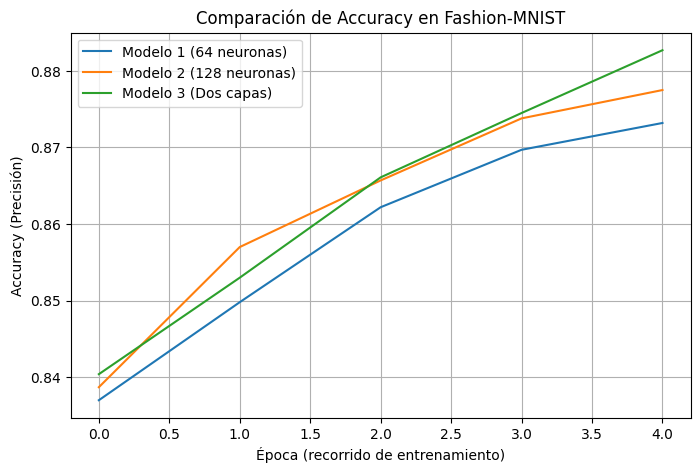

In [3]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

# Convertimos los píxeles (que van de 0 a 255) a valores entre 0 y 1
def normalizar(imagen, etiqueta):
    imagen = tf.cast(imagen, tf.float32) / 255.0
    return imagen, etiqueta

train_ds = train_ds.map(normalizar)
test_ds = test_ds.map(normalizar)


# Configuración 1: 64 neuronas
modelo_1 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28, 1)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Configuración 2: 128 neuronas
modelo_2 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28, 1)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Configuración 3: Dos capas ocultas
modelo_3 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28, 1)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])


modelo_1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo_2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo_3.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

epocas = 5

print("Entrenando Modelo 1...")
historial_1 = modelo_1.fit(train_ds, validation_data=test_ds, epochs=epocas)

print("\nEntrenando Modelo 2...")
historial_2 = modelo_2.fit(train_ds, validation_data=test_ds, epochs=epocas)

print("\nEntrenando Modelo 3...")
historial_3 = modelo_3.fit(train_ds, validation_data=test_ds, epochs=epocas)


plt.figure(figsize=(8, 5))

# Extraemos el 'accuracy' de las pruebas (validación) de cada historial
plt.plot(historial_1.history['val_accuracy'], label='Modelo 1 (64 neuronas)')
plt.plot(historial_2.history['val_accuracy'], label='Modelo 2 (128 neuronas)')
plt.plot(historial_3.history['val_accuracy'], label='Modelo 3 (Dos capas)')

plt.title('Comparación de Accuracy en Fashion-MNIST')
plt.xlabel('Época (recorrido de entrenamiento)')
plt.ylabel('Accuracy (Precisión)')
plt.legend()
plt.grid(True)
plt.show()

Al observar la gráfica, nos damos cuenta de que hacer la red un poco más grande ayuda a que se equivoque menos. El modelo 1 hizo un buen trabajo, pero cuando le dimos más "memoria" en el modelo 2 o le agregamos un paso extra para procesar la información en el modelo 3, la computadora logró aprender mejor.

Al final, el modelo 3 fue el ganador porque logró clasificar correctamente la ropa casi el 88% de las veces. Esto nos enseña que, para tareas de reconocer imágenes, a la red le sirve mucho estar un poquito más armada para poder fijarse mejor en los detalles de cada prenda.